# Initial Model Creation

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Census divisions
STATE_NAMES = ["Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut", "Delaware", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire", "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"]
CENSUS_DIVISIONS = {
    "New England": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont"],
    "Middle Atlantic": ["New Jersey", "New York", "Pennsylvania"],
    "East North Central": ["Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin"],
    "West North Central": ["Iowa", "Kansas", "Minnesota", "Missouri", "Nebraska", "North Dakota", "South Dakota"],
    "South Atlantic": ["Delaware", "District of Columbia", "Florida", "Georgia", "Maryland",
                       "North Carolina", "South Carolina", "Virginia", "West Virginia"],
    "East South Central": ["Alabama", "Kentucky", "Mississippi", "Tennessee"],
    "West South Central": ["Arkansas", "Louisiana", "Oklahoma", "Texas"],
    "Mountain": ["Arizona", "Colorado", "Idaho", "Montana", "Nevada", "New Mexico", "Utah", "Wyoming"],
    "Pacific": ["Alaska", "California", "Hawaii", "Oregon", "Washington"],
}
STATE_TO_DIVISION = {
    state_name: division_name
    for division_name, state_names in CENSUS_DIVISIONS.items()
    for state_name in state_names
}

# Federal minimum wage
FEDERAL_MINIMUM_WAGE_BY_YEAR = {2005: 5.15, 2006: 5.15, 2007: 5.85, 2008: 6.55}
FEDERAL_MINIMUM_WAGE_BY_YEAR.update({year: 7.25 for year in range(2009, 2031)})

# Variables that get lags / diffs / demeaning
BASE_VARIABLES_FOR_LAGS = ["unemployment_rate", "hpi", "minimum_wage_ratio"]
VARIABLES_TO_DEMEAN = ["unemployment_rate", "hpi", "minimum_wage_ratio"]
DEMEANED_COLUMNS = [f"{name}_state_demeaned" for name in VARIABLES_TO_DEMEAN]

df = pd.read_csv("../data/processed/fulldata.csv")
df.head()

,state,year,minimum_wage,gross_vacancy_rate,hpi,unemployment_rate
0,Alabama,2005,5.15,16.2,341.58,4.5
1,Alaska,2005,7.15,19.7,367.78,6.9
2,Arizona,2005,5.15,17.1,581.47,4.6
3,Arkansas,2005,5.15,14.6,346.51,5.3
4,California,2005,6.75,8.6,1258.18,5.4


In [27]:
def build_features(raw_dataframe):
    dataframe = raw_dataframe.sort_values(["state", "year"]).reset_index(drop=True)

    # Region
    dataframe["region_division"] = dataframe["state"].map(STATE_TO_DIVISION)
    unmapped_states = dataframe.loc[dataframe["region_division"].isna(), "state"].unique()
    if len(unmapped_states) > 0:
        raise ValueError(f"States missing from region mapping: {unmapped_states}")

    # Relative minimum wage (state minimum vs federal floor)
    dataframe["federal_minimum_wage"] = dataframe["year"].map(FEDERAL_MINIMUM_WAGE_BY_YEAR)
    dataframe["effective_minimum_wage"] = np.maximum(dataframe["minimum_wage"], dataframe["federal_minimum_wage"])
    dataframe["minimum_wage_ratio"] = dataframe["effective_minimum_wage"] / dataframe["federal_minimum_wage"]

    # Year-level national means
    for column_name in ["unemployment_rate", "hpi", "minimum_wage_ratio"]:
        dataframe[f"national_mean_{column_name}"] = dataframe.groupby("year")[column_name].transform("mean")
    dataframe["hpi_relative_to_national"] = dataframe["hpi"] / dataframe["national_mean_hpi"]
    dataframe["unemployment_minus_national"] = dataframe["unemployment_rate"] - dataframe["national_mean_unemployment_rate"]

    # Within-state changes
    state_groups = dataframe.groupby("state")
    for column_name in BASE_VARIABLES_FOR_LAGS:
        previous_value = state_groups[column_name].shift(1)
        dataframe[f"{column_name}_diff"] = dataframe[column_name] - previous_value
        dataframe[f"{column_name}_pct_change"] = dataframe[column_name] / previous_value - 1
    dataframe["hpi_growth_log"] = np.log(dataframe["hpi"]) - np.log(state_groups["hpi"].shift(1))

    # Lags of predictors (1 and 2 years)
    for column_name in BASE_VARIABLES_FOR_LAGS:
        for lag in (1, 2):
            dataframe[f"{column_name}_lag_{lag}"] = state_groups[column_name].shift(lag)

    # Lagged target (always built for the persistence baseline, only used as a feature if enabled)
    dataframe["target_lag_1"] = state_groups["gross_vacancy_rate"].shift(1)

    # Drop the first two years per state, where lags are undefined
    required_columns = [c for c in dataframe.columns if c.endswith(("_lag_1", "_lag_2", "_diff", "_pct_change"))]
    required_columns += ["hpi_growth_log", "target_lag_1"]
    rows_before = len(dataframe)
    dataframe = dataframe.dropna(subset=required_columns).reset_index(drop=True)
    print(f"Dropped {rows_before - len(dataframe)} rows with undefined lags; {len(dataframe)} remain.")
    return dataframe

def get_feature_columns():
    numeric_columns = [
        "minimum_wage_ratio", "unemployment_rate", "hpi", "hpi_relative_to_national",
        "unemployment_minus_national", "hpi_growth_log",
        "national_mean_unemployment_rate", "national_mean_hpi", "national_mean_minimum_wage_ratio",
    ]
    for column_name in BASE_VARIABLES_FOR_LAGS:
        numeric_columns += [f"{column_name}_diff", f"{column_name}_pct_change",
                            f"{column_name}_lag_1", f"{column_name}_lag_2"]
    numeric_columns += DEMEANED_COLUMNS
    numeric_columns.append("target_lag_1")
    categorical_columns = ["state", "region_division"]
    return numeric_columns, categorical_columns

In [23]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

class StateDemeaner(BaseEstimator, TransformerMixin):
    def __init__(self, columns_to_demean, state_column="state"):
        self.columns_to_demean = columns_to_demean
        self.state_column = state_column

    def fit(self, features, target=None):
        self.state_means_ = features.groupby(self.state_column)[self.columns_to_demean].mean()
        self.global_means_ = features[self.columns_to_demean].mean()
        return self

    def transform(self, features):
        features = features.copy()
        state_means = self.state_means_.reindex(features[self.state_column].values).values
        state_means = np.where(np.isnan(state_means), self.global_means_.values, state_means)  # unseen states
        for column_index, column_name in enumerate(self.columns_to_demean):
            features[f"{column_name}_state_demeaned"] = features[column_name].values - state_means[:, column_index]
        return features


def build_ridge_model(alpha):
    numeric_columns, categorical_columns = get_feature_columns()
    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("year_trend", SplineTransformer(n_knots=5, degree=3, extrapolation="constant"), ["year"]),
    ])
    return Pipeline([
        ("state_demeaner", StateDemeaner(VARIABLES_TO_DEMEAN)),
        ("preprocessor", preprocessor),
        ("ridge", Ridge(alpha=alpha)),
    ])

In [24]:
from sklearn.metrics import mean_squared_error

def make_splits(development_dataframe):
    splits = []
    last_year = development_dataframe["year"].max()
    window_start = 2015
    while window_start <= last_year:
        window_end = min(window_start + 2 - 1, last_year)
        train_positions = np.where(development_dataframe["year"] < window_start)[0]
        valid_positions = np.where(development_dataframe["year"].between(window_start, window_end))[0]
        splits.append((train_positions, valid_positions))
        window_start += 2
    return splits

def baseline_predictions(train_dataframe, valid_dataframe):
    state_means = train_dataframe.groupby("state")["gross_vacancy_rate"].mean()
    global_mean = train_dataframe["gross_vacancy_rate"].mean()
    return {
        "global_mean": np.full(len(valid_dataframe), global_mean),
        "state_mean": valid_dataframe["state"].map(state_means).fillna(global_mean).values,
        "persistence_last_year": valid_dataframe["target_lag_1"].values,
    }

def root_mean_squared_error_(true_values, predicted_values):
    return np.sqrt(mean_squared_error(true_values, predicted_values))

def cross_validate_ridge(development_dataframe, splits, alpha):
    true_chunks, predicted_chunks, year_chunks = [], [], []
    for train_positions, valid_positions in splits:
        train_dataframe = development_dataframe.iloc[train_positions]
        valid_dataframe = development_dataframe.iloc[valid_positions]
        model = build_ridge_model(alpha)
        model.fit(train_dataframe, train_dataframe["gross_vacancy_rate"])
        predicted_chunks.append(model.predict(valid_dataframe))
        true_chunks.append(valid_dataframe["gross_vacancy_rate"].values)
        year_chunks.append(valid_dataframe["year"].values)
    return np.concatenate(true_chunks), np.concatenate(predicted_chunks), np.concatenate(year_chunks)

def cross_validate_baselines(development_dataframe, splits):
    true_chunks = []
    predicted_chunks = {}
    for train_positions, valid_positions in splits:
        train_dataframe = development_dataframe.iloc[train_positions]
        valid_dataframe = development_dataframe.iloc[valid_positions]
        true_chunks.append(valid_dataframe["gross_vacancy_rate"].values)
        for baseline_name, predictions in baseline_predictions(train_dataframe, valid_dataframe).items():
            predicted_chunks.setdefault(baseline_name, []).append(predictions)
    true_values = np.concatenate(true_chunks)
    return true_values, {name: np.concatenate(chunks) for name, chunks in predicted_chunks.items()}

In [31]:
from sklearn.metrics import mean_absolute_error

raw_dataframe = pd.read_csv("../data/processed/fulldata.csv")
feature_dataframe = build_features(raw_dataframe)

holdout_start_year = feature_dataframe["year"].max() - 3 + 1
holdout_dataframe = feature_dataframe[feature_dataframe["year"] >= holdout_start_year].reset_index(drop=True)
development_dataframe = feature_dataframe[feature_dataframe["year"] < holdout_start_year].reset_index(drop=True)
print(f"Development years: {development_dataframe["year"].min()}-{development_dataframe["year"].max()}, "
      f"holdout years: {holdout_start_year}-{feature_dataframe["year"].max()}")

splits = make_splits(development_dataframe)

# ---- Baselines under the same CV splits ----
baseline_true, baseline_predicted = cross_validate_baselines(development_dataframe, splits)
print("\nCV baselines (RMSE / MAE):")
for baseline_name, predictions in baseline_predicted.items():
    valid_mask = ~np.isnan(predictions)
    print(f"  {baseline_name:<24} {root_mean_squared_error_(baseline_true[valid_mask], predictions[valid_mask]):.4f} / "
          f"{mean_absolute_error(baseline_true[valid_mask], predictions[valid_mask]):.4f}")

# ---- Ridge alpha search ----
print("\nRidge CV by alpha:")
best_alpha, best_rmse = None, np.inf
alpha_rmses = []
for alpha in np.logspace(-2, 3, 16):
    true_values, predicted_values, _ = cross_validate_ridge(development_dataframe, splits, alpha)
    current_rmse = root_mean_squared_error_(true_values, predicted_values)
    print(f"  alpha={alpha:9.4f}  RMSE={current_rmse:.4f}")
    if current_rmse < best_rmse:
        best_alpha, best_rmse = alpha, current_rmse
    alpha_rmses += [current_rmse]
print(f"\nBest alpha: {best_alpha:.4f} (CV RMSE {best_rmse:.4f})")

# ---- Residuals by year (out-of-fold) ----
true_values, predicted_values, validation_years = cross_validate_ridge(development_dataframe, splits, best_alpha)
residual_table = pd.DataFrame({"year": validation_years, "squared_error": (true_values - predicted_values) ** 2})
print("\nOut-of-fold RMSE by year:")
print(residual_table.groupby("year")["squared_error"].mean().pow(0.5).round(4).to_string())

# ---- Final holdout evaluation (touch once) ----
if holdout_dataframe is not None:
    final_model = build_ridge_model(best_alpha)
    final_model.fit(development_dataframe, development_dataframe["gross_vacancy_rate"])
    holdout_predictions = final_model.predict(holdout_dataframe)
    print("\nHOLDOUT results (RMSE / MAE):")
    print(f"  {'ridge':<24} {root_mean_squared_error_(holdout_dataframe["gross_vacancy_rate"], holdout_predictions):.4f} / "
          f"{mean_absolute_error(holdout_dataframe["gross_vacancy_rate"], holdout_predictions):.4f}")
    for baseline_name, predictions in baseline_predictions(development_dataframe, holdout_dataframe).items():
        print(f"  {baseline_name:<24} {root_mean_squared_error_(holdout_dataframe["gross_vacancy_rate"], predictions):.4f} / "
              f"{mean_absolute_error(holdout_dataframe["gross_vacancy_rate"], predictions):.4f}")

# ---- Inspect coefficients (refit on all data) ----
full_model = build_ridge_model(best_alpha)
full_model.fit(feature_dataframe, feature_dataframe["gross_vacancy_rate"])
coefficient_table = pd.Series(
    full_model.named_steps["ridge"].coef_,
    index=full_model.named_steps["preprocessor"].get_feature_names_out(),
)
non_state_coefficients = coefficient_table[~coefficient_table.index.str.startswith("categorical__state_")]
print("\nLargest non-state coefficients:")
print(non_state_coefficients.reindex(non_state_coefficients.abs().sort_values(ascending=False).index).head(15).round(4).to_string())

Dropped 102 rows with undefined lags; 969 remain.
Development years: 2007-2022, holdout years: 2023-2025

CV baselines (RMSE / MAE):
  global_mean              3.8955 / 3.3029
  state_mean               2.3848 / 1.9459
  persistence_last_year    1.1318 / 0.8498

Ridge CV by alpha:
  alpha=   0.0100  RMSE=2.2578
  alpha=   0.0215  RMSE=1.9570
  alpha=   0.0464  RMSE=1.7358
  alpha=   0.1000  RMSE=1.5692
  alpha=   0.2154  RMSE=1.4495
  alpha=   0.4642  RMSE=1.3767
  alpha=   1.0000  RMSE=1.3454
  alpha=   2.1544  RMSE=1.3338
  alpha=   4.6416  RMSE=1.3184
  alpha=  10.0000  RMSE=1.2946
  alpha=  21.5443  RMSE=1.2718
  alpha=  46.4159  RMSE=1.2643
  alpha= 100.0000  RMSE=1.3104
  alpha= 215.4435  RMSE=1.4990
  alpha= 464.1589  RMSE=1.8922
  alpha=1000.0000  RMSE=2.3948

Best alpha: 46.4159 (CV RMSE 1.2643)

Out-of-fold RMSE by year:
year
2015    1.3837
2016    1.0241
2017    1.0261
2018    1.1542
2019    0.8710
2020    0.9851
2021    1.5914
2022    1.7827

HOLDOUT results (RMSE / MAE):
 

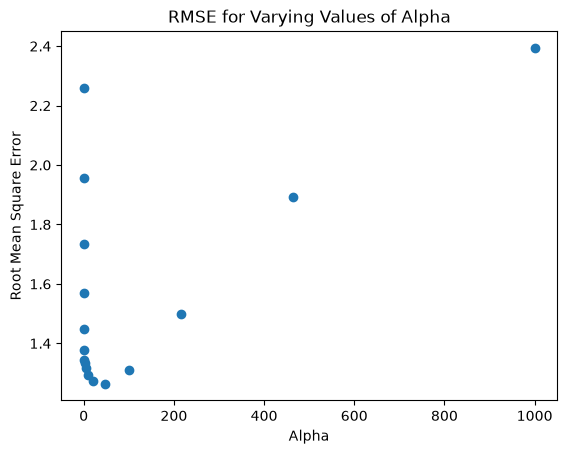

In [48]:
plt.scatter(np.logspace(-2, 3, 16), alpha_rmses)
plt.xlabel("Alpha")
plt.ylabel("Root Mean Square Error")
plt.title("RMSE for Varying Values of Alpha")
plt.show()

numeric__target_lag_1                              3.2994
year_trend__year_sp_4                             -0.3236
year_trend__year_sp_1                              0.2986
numeric__national_mean_minimum_wage_ratio         -0.2877
categorical__region_division_West North Central   -0.2846
categorical__region_division_New England           0.2373
numeric__hpi_state_demeaned                        0.2091
year_trend__year_sp_3                             -0.1934
categorical__region_division_East North Central   -0.1900
numeric__unemployment_rate_diff                   -0.1409
numeric__hpi_growth_log                           -0.1387
categorical__region_division_Pacific               0.1357
numeric__unemployment_rate_lag_2                  -0.1335
numeric__national_mean_unemployment_rate          -0.1164
year_trend__year_sp_2                              0.1112


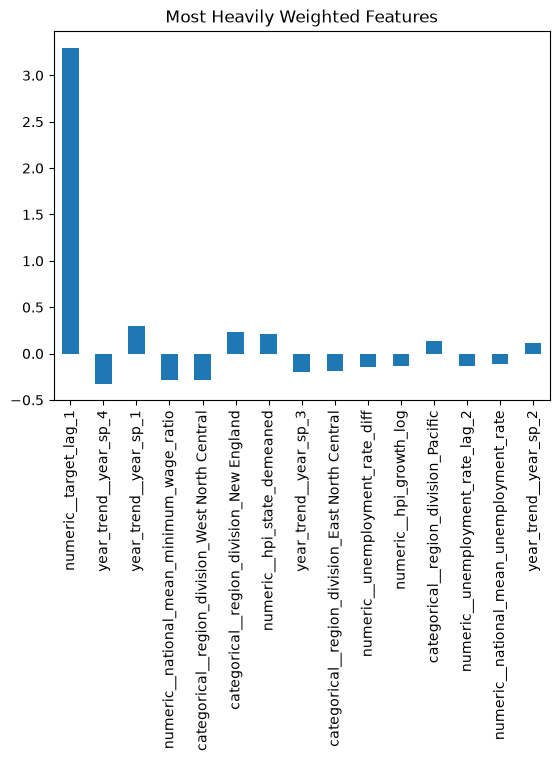

In [42]:
print(non_state_coefficients.reindex(non_state_coefficients.abs().sort_values(ascending=False).index).head(15).round(4).to_string())
ax = non_state_coefficients.reindex(non_state_coefficients.abs().sort_values(ascending=False).index).head(15).round(4).plot(kind='bar', title='Most Heavily Weighted Features')

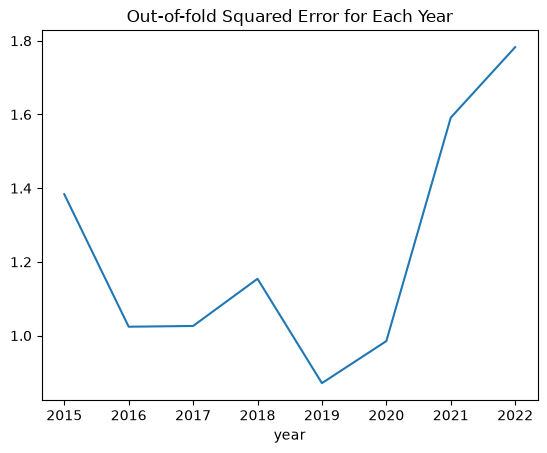

In [46]:
ax = residual_table.groupby("year")["squared_error"].mean().pow(0.5).round(4).plot(x="year", y="squared_error", title="Out-of-fold Squared Error for Each Year")